# MethaneScope AI · Lesson 2.8
## Controlled failure testing and reliable recovery

**Prerequisite:** Lesson 2.6 monitoring code and Lesson 2.7 dashboard. You verified 1 real NASA EMIT candidate in PostGIS, 1 stored feature, and 11 passing tests.

**Mission:** Prove that an operational pipeline fails *safely* when inputs are missing, validation fails, or a database insertion fails. All failure drills here use **temporary folders and mocks**. They do **not** stop Docker, modify your real PostGIS database, corrupt NASA files, or overwrite your operational monitoring history.

**Scientific integrity:** A `SUCCESS` run means the *engineering workflow* succeeded; it does not establish the scientific validity of methane retrievals. A `SKIPPED` duplicate is a successful idempotent operation.

### Objectives

1. Read production monitoring audit data without modifying it.
2. Distinguish `PREFLIGHT`, `DATA_VALIDATION`, `INGESTION`, and `EXCEPTION` failures.
3. Demonstrate that preflight/validation failures prevent database writes.
4. Inspect local alerts and append-only run-history files.
5. Verify a recovered run while keeping the original NASA granule intact.

> You will simulate errors, not create outages. Run the cells sequentially with **Shift+Enter**.

In [1]:
from pathlib import Path
import json
import tempfile
from unittest.mock import patch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from methanescope import monitor, pipeline

PROJECT = Path.cwd().resolve()
assert (PROJECT / 'methanescope' / 'monitor.py').exists(), (
    'Open this notebook from your MethaneScope project root.'
)
print('Project:', PROJECT)
print('Lesson 2.8 environment ready')

Project: C:\Users\SOOQ ELASER\OneDrive\Desktop\RemoteSensing\MethaneScope
Lesson 2.8 environment ready


## A · Examine the real operational history (read-only)

The history below contains *actual* local monitoring events written by Lesson 2.6. We will not append to or change them.

In [2]:
history_path = PROJECT / 'outputs' / 'monitoring' / 'run_history.jsonl'
actual_events = monitor.read_history(history_path, limit=1000)
print('Real monitored executions:', len(actual_events))
if actual_events:
    view = pd.DataFrame(actual_events)
    cols = [c for c in ['started_utc','result','failure_class','duration_seconds','message'] if c in view.columns]
    display(view[cols].tail(10))
else:
    print('No real history yet. This does not block the simulated drills.')

Real monitored executions: 1


,started_utc,result,failure_class,duration_seconds,message
0,2026-10-18T11:32:25+00:00,SUCCESS,None,1.735,Validation and transactional ingestion completed


## B · Simulate prerequisite failure

Examples include an unavailable PostGIS instance, missing accepted manifest, or missing source files. Correct response: **block ingestion before executing the pipeline**.

In [3]:
def pretend_health(status='OK'):
    return {'status': status,
            'checks': [{'check':'training_simulation','status':status,'detail':'synthetic drill'}],
            'scientific_validation':'NOT_ESTABLISHED'}

with tempfile.TemporaryDirectory(prefix='methanescope_l28_') as scratch:
    with patch.object(monitor, 'health_snapshot', return_value=pretend_health('CRITICAL')):
        result_preflight = monitor.run_once(Path(scratch))
    print('Simulated result:', result_preflight['result'])
    print('Failure category:', result_preflight['failure_class'])
    print('Pipeline blocked before validation:', 'validation_exit_code' not in result_preflight)
    print('Alert written in temporary folder:', (Path(scratch)/'outputs'/'monitoring'/'alerts.jsonl').exists())
assert result_preflight['result']=='FAILED'
assert result_preflight['failure_class']=='PREFLIGHT'

Simulated result: FAILED
Failure category: PREFLIGHT
Pipeline blocked before validation: True
Alert written in temporary folder: True


## C · Simulate data validation failure

The validation step should fail, and ingestion should **never** be called. We replace the CLI function with a controlled fake, so no database access is possible in this drill.

In [4]:
calls_validation = []
def fail_validation(args):
    calls_validation.append(args[0])
    if args[0] == 'validate':
        return 1
    raise AssertionError('Ingest must not run after validation failure')

with tempfile.TemporaryDirectory(prefix='methanescope_l28_') as scratch:
    with patch.object(monitor, 'health_snapshot', return_value=pretend_health('OK')):
        with patch.object(pipeline, 'run', side_effect=fail_validation):
            result_validation = monitor.run_once(Path(scratch))
    print('Result:',result_validation['result'])
    print('Failure category:',result_validation['failure_class'])
    print('Commands called:',calls_validation)
assert calls_validation==['validate']
assert result_validation['failure_class']=='DATA_VALIDATION'

Result: FAILED
Failure category: DATA_VALIDATION
Commands called: ['validate']


## D · Simulate ingestion failure

This drill assumes validation succeeds but insertion does not. The monitor should record `INGESTION`, leaving evidence for investigation. A real database error might instead raise an exception and be labelled `EXCEPTION` by the current wrapper.

In [5]:
calls_ingest=[]
def fail_ingestion(args):
    calls_ingest.append(args[0])
    return 0 if args[0]=='validate' else 1

with tempfile.TemporaryDirectory(prefix='methanescope_l28_') as scratch:
    with patch.object(monitor, 'health_snapshot', return_value=pretend_health('OK')):
        with patch.object(pipeline, 'run', side_effect=fail_ingestion):
            result_ingestion = monitor.run_once(Path(scratch))
    print('Result:', result_ingestion['result'])
    print('Failure category:', result_ingestion['failure_class'])
    print('Commands called:', calls_ingest)
assert calls_ingest==['validate','ingest']
assert result_ingestion['failure_class']=='INGESTION'

Result: FAILED
Failure category: INGESTION
Commands called: ['validate', 'ingest']


## E · Simulate successful recovery

Now simulate valid prerequisites, a successful validation, and successful ingestion. We deliberately avoid touching the real database or raw files.

In [6]:
calls_success=[]
def pass_pipeline(args):
    calls_success.append(args[0])
    return 0

with tempfile.TemporaryDirectory(prefix='methanescope_l28_') as scratch:
    scratch=Path(scratch)
    with patch.object(monitor, 'health_snapshot', return_value=pretend_health('OK')):
        with patch.object(pipeline, 'run', side_effect=pass_pipeline):
            result_success = monitor.run_once(scratch)
    recorded = monitor.read_history(scratch/'outputs'/'monitoring'/'run_history.jsonl')
    print('Recovered result:', result_success['result'])
    print('Commands called:', calls_success)
    print('History entries:', len(recorded))
    print('Local failure alerts exist:', (scratch/'outputs'/'monitoring'/'alerts.jsonl').exists())
assert result_success['result']=='SUCCESS'
assert calls_success==['validate','ingest']

Recovered result: SUCCESS
Commands called: ['validate', 'ingest']
History entries: 1
Local failure alerts exist: False


## F · Compare the simulations

The following chart is **simulated monitoring data**. Do not combine it with real production reliability statistics.

,scenario,outcome,failure_class
0,Preflight blocked,FAILED,PREFLIGHT
1,Bad input,FAILED,DATA_VALIDATION
2,Ingestion error,FAILED,INGESTION
3,Recovery,SUCCESS,None


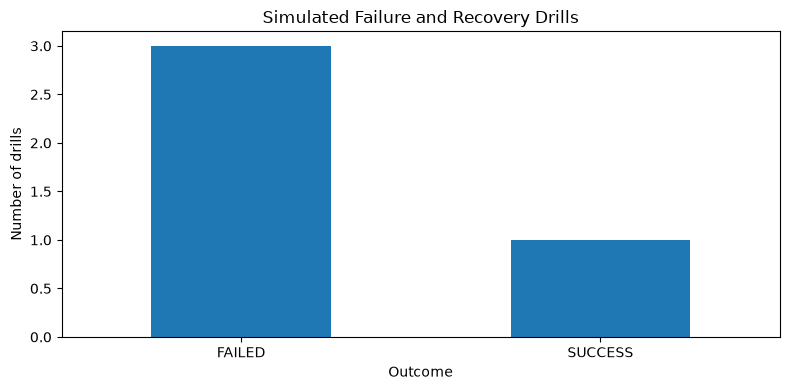

In [7]:
simulated = pd.DataFrame([
    {'scenario':'Preflight blocked','outcome':result_preflight['result'],'failure_class':result_preflight['failure_class']},
    {'scenario':'Bad input','outcome':result_validation['result'],'failure_class':result_validation['failure_class']},
    {'scenario':'Ingestion error','outcome':result_ingestion['result'],'failure_class':result_ingestion['failure_class']},
    {'scenario':'Recovery','outcome':result_success['result'],'failure_class':result_success['failure_class']},
])
display(simulated)
counts = simulated['outcome'].value_counts()
ax=counts.plot(kind='bar', figsize=(8,4), title='Simulated Failure and Recovery Drills')
ax.set_xlabel('Outcome')
ax.set_ylabel('Number of drills')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## G · Validate with automated tests

The companion package provides `tests/test_reliability.py` using pytest mocks. It only creates temporary test files. Run the following from Git Bash:

```bash
python -m pytest -q tests/test_science.py tests/test_monitor.py tests/test_reliability.py
```

Expected: the prior 11 tests **plus 5 reliability tests = 16 tests** if your installed modules match the Lesson 2.6 starter.

Do not enable automated schedules or kill your real database for this lesson. Safe scheduling will require explicit configuration, concurrency control, retries with backoff and monitoring.

### Written checkpoint

1. Why must ingestion not execute after a validation failure?
2. How is `PREFLIGHT` different from `DATA_VALIDATION`?
3. Why is a failure alert in `alerts.jsonl` not equivalent to an external notification?
4. Why are temporary-directory tests preferable to deleting real NASA files?
5. Why is one successful operational run insufficient evidence of production reliability?

### Completion condition

The simulated four scenarios behave as expected, all existing and new tests pass, and your real NASA/PostGIS observations remain untouched.